# Введение

Teachable Machine – это веб-версия инструмента, которая позволяет всем желающим легко создать модель машинного обучения.

Чтобы научить компьютер распознавать изображения, звуки и позы с помощью Teachable Machine не нужно писать код. Вы можете использовать модель в своих проектах, на сайтах, в приложениях и не только.

Сервис Teachable Machine доступен по ссылке [teachablemachine.withgoogle.com](teachablemachine.withgoogle.com).  Язык пользовательского интерфейса - русский.

Перед обучением модели рекомендуем внимательно изучить дополнительную информацию, расположенную на главной странице сервиса:

* Что такое Teachable Machine?

* Как пользоваться инструментом?

* С помощью чего можно обучить модель?

* Руководства

# Проекты с изображениями.

## Задание 1. 

1. Перейдите по ссылке [teachablemachine.withgoogle.com](teachablemachine.withgoogle.com) и нажмите "Начать".

2. Выберите "Проект с изображениями", далее "Стандартная модель изображения".

Необходимо обучить модель различать две группы изображений: хот-доги и не хот-доги с помощью готового (размеченного) набора изображений.

3. Переименуйте "Class 1" в "хот-доги", а "Class 2" в "не хот-доги".

4. В классе "хот-доги" нажмите на кнопку "Загрузить", затем выберите пункт "Выберите изображения из файлов".

5. Выберите папку "hot_dog_train". Необходимо выбрать все изображения в папке с помощью клавиш Ctrl+A и нажать "Открыть".

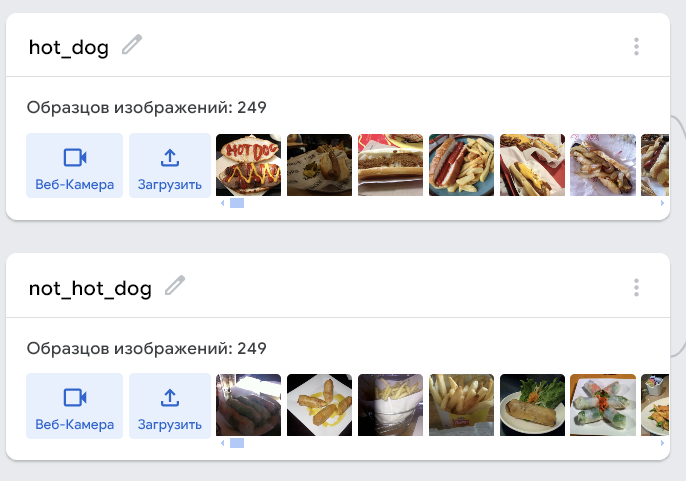

6. Аналогично нужно добавить изображения из папки "not_hot_dog_train" в класс "не хот-доги".
7. Запустите обучение модели, нажав на кнопку "Обучить модель". Обучение происходит на текущей вкладке браузера некоторое время, поэтому не следует переключаться между вкладками во время процесса обучения.
8. В разделе "Обучение" раскройте список "Дополнительно" и выберите "Дополнительные сведения". Они откроются справа. Изучите данный раздел. Обратите внимание на раздел "Точность на каждый класс".

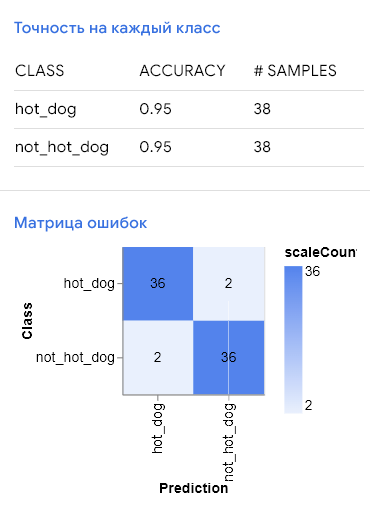

9. Справа от раздела "Обучение" находится раздел "Посмотреть", в котором можно проверить, как работает обученная модель. Для этого вместо "webcam" нужно выбрать "файл" и выбрать один файл из папки "hot_dog_validation".

10. Посмотрите результат (прогноз) в разделе "Выходные данные" и сделайте вывод, насколько правильно модель определила наличие хот-дога на изображении. Загрузите поочередно еще 10 изображений и проверьте правильность определения "хот-догов". __Напишите вывод в отчете__.

11. Аналогичным образом загрузите поочередно 10 изображений из папки "not_hot_dog_validation". Сделайте вывод о правильности определения "не хот-догов". __Напишите вывод в отчете__.

12. Сохраните модель. 
13. Изучите и скопируйте фрагмент кода, который можно использовать в вашей модели. Используя фрагмент кода, загрузите модель в jupyter notebook и проверьте ее работу на всех изображениях (папки hot_dog_validation и not_hot_dog_validation).

## Отчет 
Модель работает довольно хорошо: хот-доги она узнает правильно в 82% случаев, а не хот-доги — в 87%. В среднем точность около 84%.
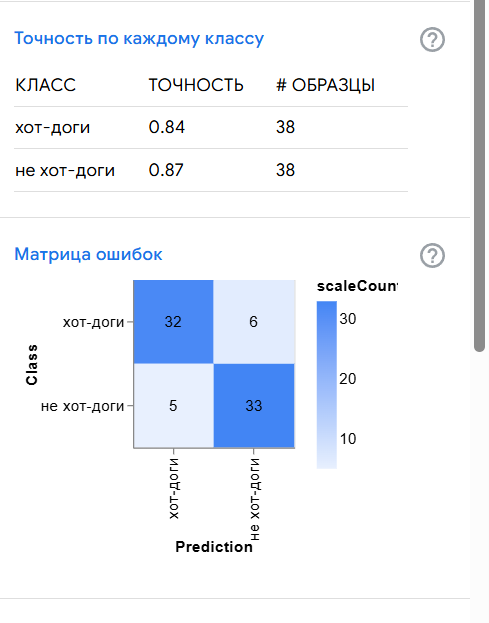

##  хот-доги

Тестирование показало, что модель отлично справляется, когда видит объект четко. Если на фото хорошо видна сосиска в тесте, модель распознает хот-дог с уверенностью 99%.

Однако есть и слабые места. Когда сосиски на картинке не видно (например, она закрыта или фото необычное), уверенность модели падает до 34%. А если на изображении сразу несколько хот-догов вместе с картошкой фри, модель теряется и выдает всего 19%.

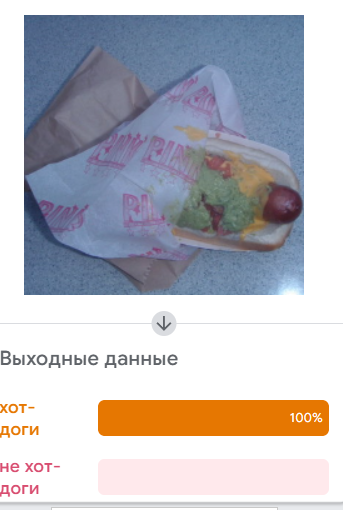 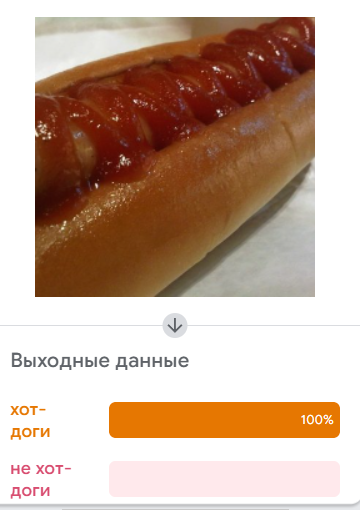

## не хот-доги

Модель хорошо понимает, что не является хот-догом. Например, мороженое она со стопроцентной уверенностью отнесла к классу «не хот-доги».

Когда я показал ей блюдо, которое по размеру и форме напоминает хот-дог, модель засомневалась: дала 30% за то, что это хот-дог, и 70% - что это не хот-дог. То есть она не обманулась внешним сходством и всё равно склонилась к правильному варианту.

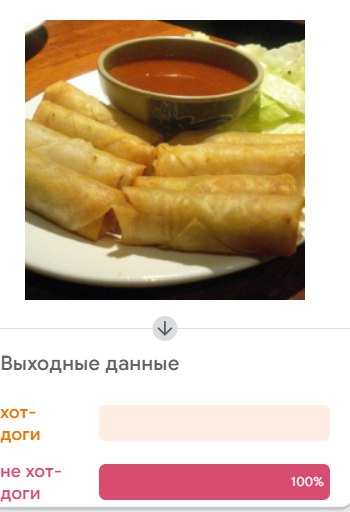 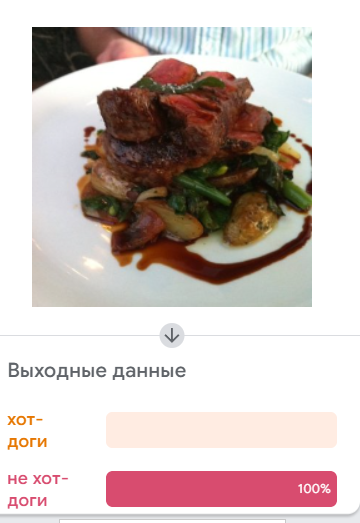

In [14]:
pip install "tensorflow==2.21.0"

In [6]:
from keras.models import load_model 
from PIL import Image, ImageOps
import numpy as np

np.set_printoptions(suppress=True)

model = load_model(
    r"C:\Users\ilnar\Downloads\TeachableMachine_Data\converted_keras\keras_model.h5",
    compile=False
)

class_names = open(
    r"C:\Users\ilnar\Downloads\TeachableMachine_Data\converted_keras\labels.txt",
    "r", encoding="utf-8"
).readlines()

# Массив нужной формы
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Путь к одной картинке
image = Image.open(
    r"C:\Users\ilnar\Downloads\TeachableMachine_Data\hot_dog_validation-20240303T060924Z-001\hot_dog_validation\133012.jpg"
).convert("RGB")

size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# В массив и нормализация
image_array = np.asarray(image)
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
data[0] = normalized_image_array

# Прогноз
prediction = model.predict(data, verbose=0)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

Class: хот-доги
Confidence Score: 0.99841416


In [2]:
import os
import numpy as np
from PIL import Image, ImageOps
from keras.models import load_model
import warnings
warnings.filterwarnings("ignore")

MODEL_PATH  = r"C:\Users\ilnar\Downloads\TeachableMachine_Data\converted_keras\keras_model.h5"
LABELS_PATH = r"C:\Users\ilnar\Downloads\TeachableMachine_Data\converted_keras\labels.txt"
HOT_DOG_DIR     = r"C:\Users\ilnar\Downloads\TeachableMachine_Data\hot_dog_validation-20240303T060924Z-001\hot_dog_validation"
NOT_HOT_DOG_DIR = r"C:\Users\ilnar\Downloads\TeachableMachine_Data\not_hot_dog_validation-20240303T060915Z-001\not_hot_dog_validation"

model = load_model(MODEL_PATH, compile=False)
class_names = [c.strip() for c in open(LABELS_PATH, "r", encoding="utf-8").readlines()]

# Предсказания
def predict_image(image_path):
    data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
    image = Image.open(image_path).convert("RGB")
    size = (224, 224)
    image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
    image_array = np.asarray(image)
    normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
    data[0] = normalized_image_array
    prediction = model.predict(data, verbose=0)
    index = int(np.argmax(prediction))
    class_name = class_names[index][2:]        
    confidence_score = float(prediction[0][index])
    return class_name, confidence_score


print("Проверка хот-догов")
hot_files = os.listdir(HOT_DOG_DIR)
hot_correct = 0
hot_total = 0

for file in hot_files:
    if file.endswith(('.jpg')):
        hot_total += 1
        path = os.path.join(HOT_DOG_DIR, file)
        pred, conf = predict_image(path)
        if pred == "хот-доги":
            hot_correct += 1
            print(file, " Верно")
        else:
            print(file, " Ошибка")


print("\n Проверка не хот-догов")
not_hot_files = os.listdir(NOT_HOT_DOG_DIR)
not_hot_correct = 0
not_hot_total = 0

for file in not_hot_files:
    if file.endswith(('.jpg')):
        not_hot_total += 1
        path = os.path.join(NOT_HOT_DOG_DIR, file)
        pred, conf = predict_image(path)
        if pred == "не хот-доги":
            not_hot_correct += 1
            print(file, " Верно")
        else:
            print(file, " Ошибка")



print("\n Итог")
print(f"Хот-доги:    {hot_correct}/{hot_total} = {hot_correct/hot_total*100:.1f}%")
print(f"Не хот-доги: {not_hot_correct}/{not_hot_total} = {not_hot_correct/not_hot_total*100:.1f}%")

total_correct = hot_correct + not_hot_correct
total_all = hot_total + not_hot_total
print(f"Средняя точность: {total_correct}/{total_all} = {total_correct/total_all*100:.1f}%")

Проверка хот-догов
133012.jpg  Верно
133015.jpg  Ошибка
133245.jpg  Верно
135628.jpg  Верно
138933.jpg  Верно
138937.jpg  Верно
138969.jpg  Верно
139177.jpg  Верно
142835.jpg  Верно
143012.jpg  Верно
144956.jpg  Верно
146227.jpg  Верно
146834.jpg  Верно
147874.jpg  Верно
152106.jpg  Верно
154409.jpg  Ошибка
154545.jpg  Верно
156126.jpg  Верно
156135.jpg  Верно
160274.jpg  Верно
160523.jpg  Верно
161911.jpg  Верно
165005.jpg  Верно
170212.jpg  Верно
170452.jpg  Верно
171607.jpg  Верно
171875.jpg  Верно
173995.jpg  Верно
180961.jpg  Верно
183400.jpg  Верно
189511.jpg  Верно
190809.jpg  Верно
193755.jpg  Верно
195251.jpg  Верно
197257.jpg  Верно
198641.jpg  Верно
200438.jpg  Верно
201986.jpg  Верно
206995.jpg  Верно
207291.jpg  Верно
207335.jpg  Ошибка
209306.jpg  Верно
210271.jpg  Верно
210861.jpg  Верно
211824.jpg  Ошибка
212515.jpg  Верно
219273.jpg  Верно
219922.jpg  Верно
224850.jpg  Верно
225367.jpg  Ошибка
233179.jpg  Верно
238581.jpg  Верно
248122.jpg  Верно
250715.jpg  Верно
2590

### Вывод
- Результаты проверки:

- Хот-доги: 217 из 250 верно (86.8%)

- Не хот-доги: 219 из 250 верно (87.6%)

- Средняя точность: 436 из 500 (87.2%)

## Задание 2. 

1. Соберите коллекцию изображений как минимум трех классов (можно сделать больше классов). В каждом классе должно быть минимум 20 изображений. Можно использовать изображения из интернета или создать собственные изображения с помощью камеры.

2. Обучите модель в сервисе Teachable Machine.

3. В отчете укажите названия классов и точность на каждый класс. Добавьте скриншоты.

4. Сделайте вывод, как точно модель определяет неизвестные ей изображения.

5. Сохраните модель.
6. Используя фрагмент кода, загрузите модель в jupyter notebook и проверьте ее работу на нескольких изображениях.

## Отчет 2

Для обучения модели было выбрано 4 класса:

Яблоки, Бананы, Ананасы, Прочее

Точность модели:

Яблоки: Точность 0.80.

Бананы: Точность 0.75.

Ананасы: Точность 0.75. 

Прочее: Точность 0.75. 

Модель была проверена на 17 изображениях, распределенных по 4 классам.

Наилучший результат показал класс «Яблоки» - точность 0.80. Из 5 изображений модель верно определила 4, однако одно яблоко было ошибочно отнесено к категории «Прочее».

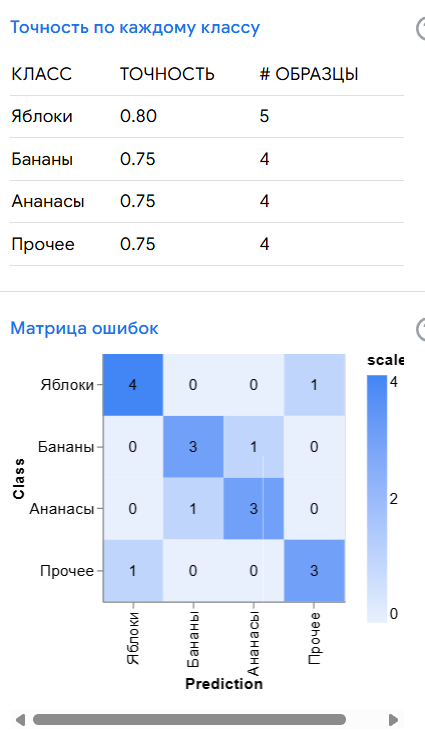


#### Проверка модели на новых предметах:

Банан - модель уверенно распознала его как «Банан» с вероятностью 95%.

Кожура от банана - также правильно классифицирована как «Банан» с уверенностью 98% (модель хорошо определяет признаки объекта, несмотря на изменение его формы).

Яблоко - распознано как «Яблоко» с уверенностью 90%.

Ананас - распознан как «Ананас» с уверенностью 100%.

Проверка на предметах из категории «Прочее»:

Свекла - модель отнесла к классу «Прочее» со 100% уверенностью.

Морковь - отнесена к классу «Прочее» с уверенностью 94%.


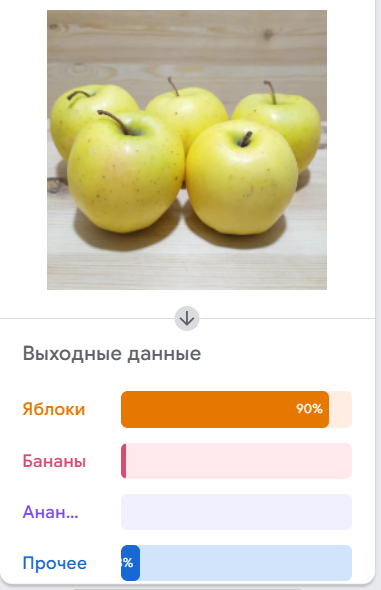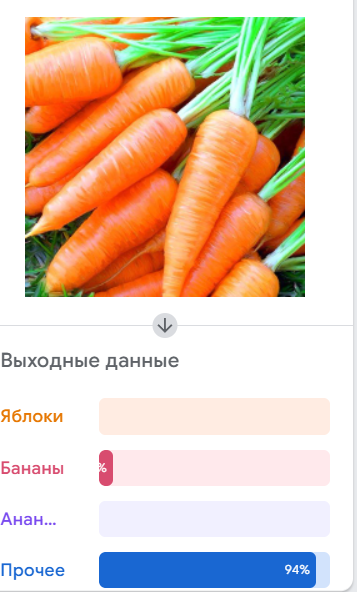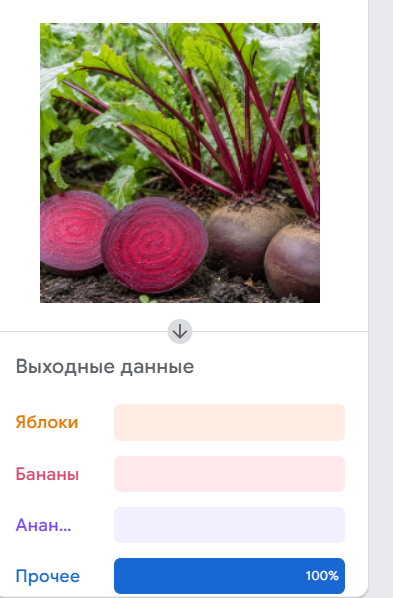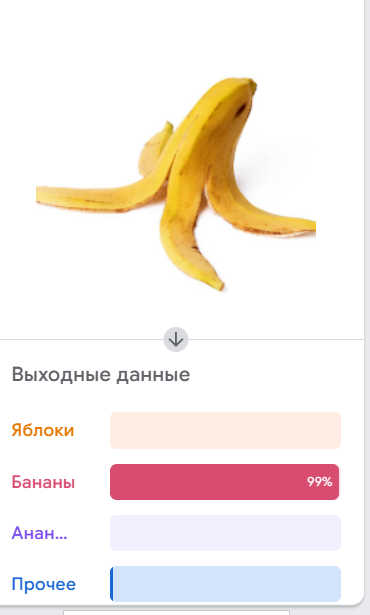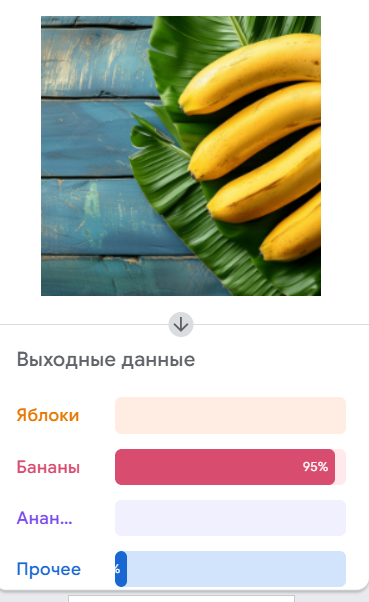 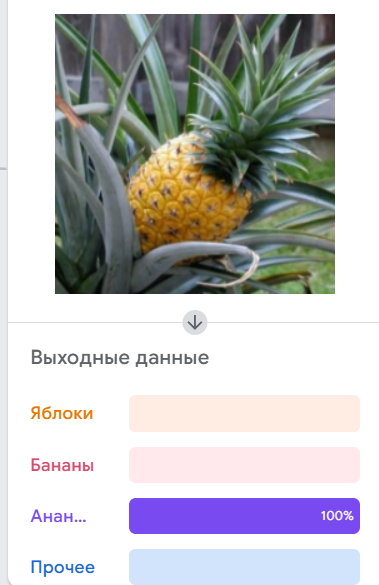

In [ ]:
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np
import os

# Отключаем научную нотацию
np.set_printoptions(suppress=True)

# 1. Загружаем модель и метки (ваш фрагмент)
# Указываем полный путь к модели из папки converted_keras
model_path = r"C:\Users\ilnar\Downloads\TeachableMachine_Data\converted_keras\keras_model.h5"
labels_path = r"C:\Users\ilnar\Downloads\TeachableMachine_Data\converted_keras\labels.txt"

model = load_model(model_path, compile=False)
class_names = open(labels_path, "r", encoding="utf-8").readlines()

# 2. Список картинок для проверки. 
# Сюда можно вписать любые картинки (хоть хот-доги, хоть фрукты, которые вы проверяли на веб-камеру)
image_paths = [
    r"C:\Users\ilnar\Downloads\TeachableMachine_Data\hot_dog_validation-20240303T060924Z-001\hot_dog_validation\133012.jpg",
    r"C:\Users\ilnar\Downloads\TeachableMachine_Data\not_hot_dog_validation-20240303T060915Z-001\not_hot_dog_validation\13023.jpg"
    # Можете добавить свои пути ниже через запятую
]

# 3. Цикл проверки для каждой картинки
for image_path in image_paths:
    # Проверяем, существует ли файл (чтобы не было ошибки)
    if not os.path.exists(image_path):
        print(f"Файл не найден: {image_path}")
        continue
        
    print(f"\n--- Проверяем файл: {os.path.basename(image_path)} ---")
    
    # Логика из фрагмента Teachable Machine
    data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
    image = Image.open(image_path).convert("RGB")
    size = (224, 224)
    image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
    image_array = np.asarray(image)
    normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
    data[0] = normalized_image_array

    # Предсказание
    prediction = model.predict(data, verbose=0)
    index = np.argmax(prediction)
    class_name = class_names[index]
    confidence_score = prediction[0][index]

    # Вывод результата
    print("Class:", class_name[2:].strip())
    print("Confidence Score:", round(float(confidence_score), 3))

## Задание 3.

Pocket AutoML — это Android-приложение, которое позволяет тренировать модели глубокого обучения (deep learning) для классификации изображений без написания кода. Есть возможность экспортировать модель в формате TensorFlow Lite и создать на основе этой модели собственное Android-приложение, для чего прилагается пошаговое руководство.

Тренировка работает прямо на устройстве, за счёт этого для неё не требуется подключение к интернету, нет проблем с конфиденциальностью, т.к. изображения не покидают устройства пользователя. Теми же преимуществами будут обладать и приложения, созданные на основе экспортированных из Pocket AutoML моделей. Единственная функция, требующая подключения к интернету, это экспорт в TensorFlow Lite.

1. Установите приложение Pocket AutoML на свой смартфон.
2. Создайте новую задачу.
3. Создайте минимум 3 класса объектов, которые будут использоваться в модели распознавания образов.
4. На вкладке "Данные" в каждый класс добавьте минимум по 10 изображений (можно использовать камеру или загрузить готовые изображения).
5. На вкладке "Модель" выполните тренировку модели.
6. На вкладке "Распознать" проверьте качество распознавания изображений, показывая модели поочередно несколько объектов (можно использовать камеру или загрузить готовые изображения). При распознавании помогите модели работать лучше, подтвердив или исправив результат распознавания. После каждого нового распознавания и подтверждения изображение добавляется в соответствующий класс. Распознайте как минимум 10 изображений.
7. Снова выполните тренировку модели. После этого снова проверьте качество распознавания, предлагая модели новые изображения.
8. Сделайте скриншоты вкладок "Данные" и "Модель". Разместите эти скриншоты в отчет.
9. В отчете напишите вывод о качестве распознавания изображений вашей модели. Попытайтесь объяснить причины, почему модель в некоторых случаях ошибается.

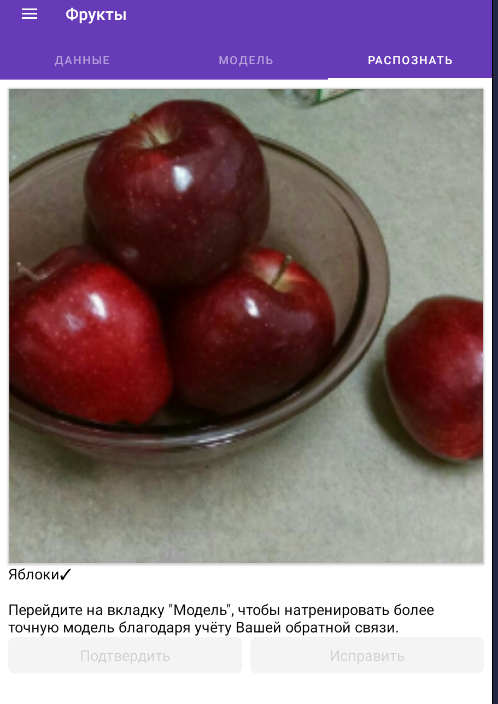 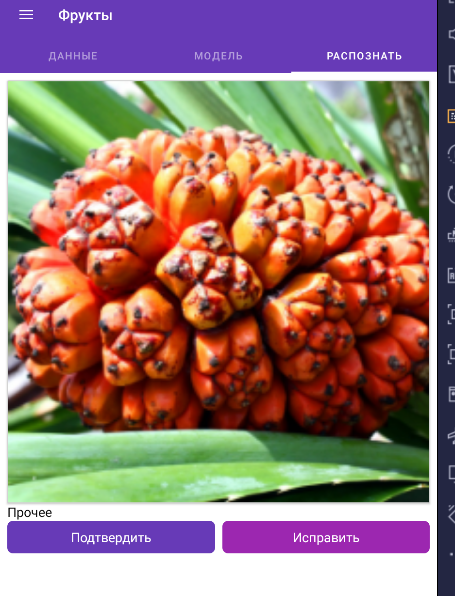 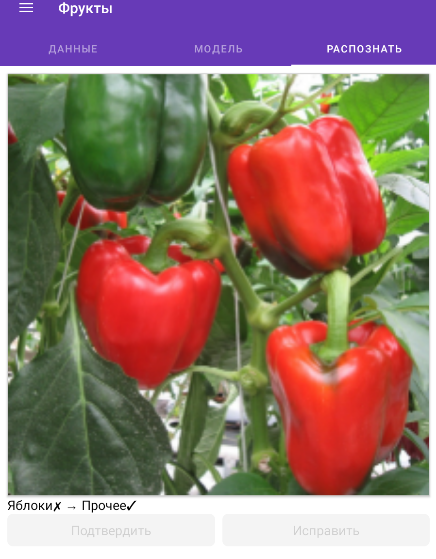 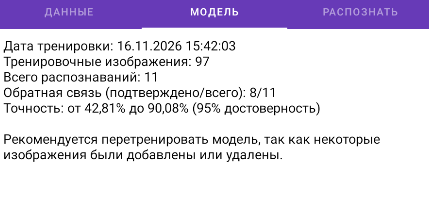 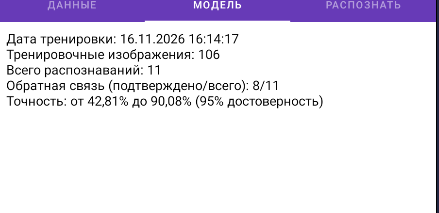 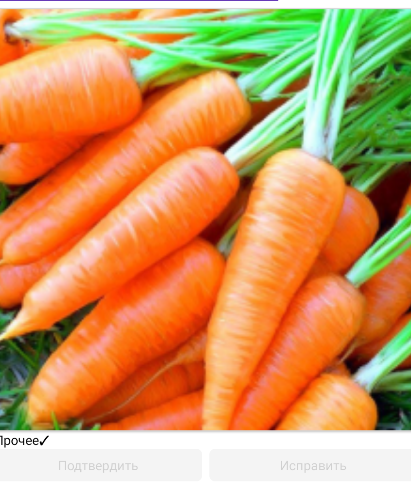  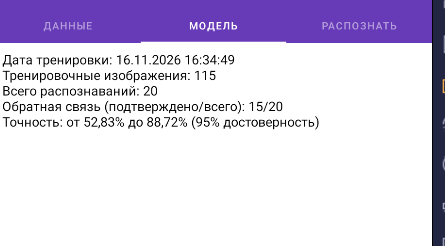 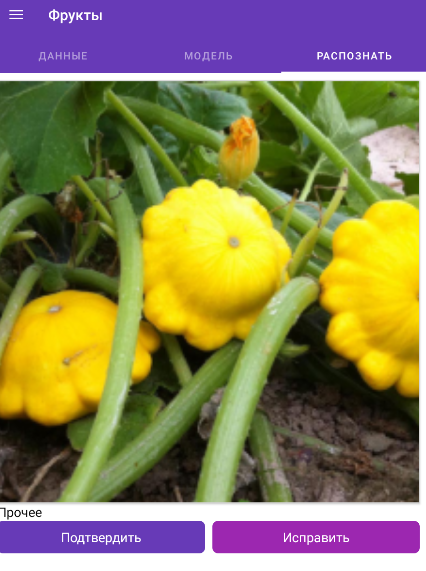

## Задание 4.

1. Разработайте программный интерфейс для модели машинного обучения. API должен позволить приложению пользователя получить результат и точность распознавания.
2. Разработайте приложение с графическим интерфейсом, которое должно позволить загрузить изображение и с помощью разработанного API показать результат распознавания.